# PROGETTO DI TRATTAMENTO DELL'INCERTEZZA
****TRACCIA:****
Stimare l'ATE sul dataset NSW pesandolo per la probabilità soft di appartenenza a un cluster di una GMM

In [1]:
import pandas as pd
import numpy as np

# Matching
from cem.match import match
from cem.coarsen import coarsen
from cem.imbalance import L1
import statsmodels.api as sm

# Causal graph
import dowhy
from dowhy import CausalModel
import matplotlib.pyplot as plt

# Gaussian mixture model
import itertools
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# Scikit-Learn Imports
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor)

# Model Selection & Metrics
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Ale plot
import math
from PyALE import ale

C:\Users\ACER\anaconda3\envs\FDP\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_nsw = pd.read_csv("nsw74demo.csv")
df_nsw = df_nsw.drop(columns= 'rownames')
df_nsw

,trt,age,educ,black,hisp,marr,nodeg,re74,re75,re78
0,0,23,10,1,0,0,1,0.00,0.00,0.000
1,0,26,12,0,0,0,0,0.00,0.00,12383.680
2,0,22,9,1,0,0,1,0.00,0.00,0.000
3,0,18,9,1,0,0,1,0.00,0.00,10740.080
4,0,45,11,1,0,0,1,0.00,0.00,11796.470
...,...,...,...,...,...,...,...,...,...,...
440,1,33,12,1,0,1,0,20279.95,10941.35,15952.600
441,1,25,14,1,0,1,0,35040.07,11536.57,36646.950
442,1,35,9,1,0,1,1,13602.43,13830.64,12803.970
443,1,35,8,1,0,1,1,13732.07,17976.15,3786.628


In [3]:
df_nsw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 445 entries, 0 to 444
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   trt     445 non-null    int64  
 1   age     445 non-null    int64  
 2   educ    445 non-null    int64  
 3   black   445 non-null    int64  
 4   hisp    445 non-null    int64  
 5   marr    445 non-null    int64  
 6   nodeg   445 non-null    int64  
 7   re74    445 non-null    float64
 8   re75    445 non-null    float64
 9   re78    445 non-null    float64
dtypes: float64(3), int64(7)
memory usage: 34.9 KB


In [4]:
df_nsw[df_nsw['trt']== 1]

,trt,age,educ,black,hisp,marr,nodeg,re74,re75,re78
260,1,37,11,1,0,1,1,0.00,0.00,9930.0460
261,1,22,9,0,1,0,1,0.00,0.00,3595.8940
262,1,30,12,1,0,0,0,0.00,0.00,24909.4500
263,1,27,11,1,0,0,1,0.00,0.00,7506.1460
264,1,33,8,1,0,0,1,0.00,0.00,289.7899
...,...,...,...,...,...,...,...,...,...,...
440,1,33,12,1,0,1,0,20279.95,10941.35,15952.6000
441,1,25,14,1,0,1,0,35040.07,11536.57,36646.9500
442,1,35,9,1,0,1,1,13602.43,13830.64,12803.9700
443,1,35,8,1,0,1,1,13732.07,17976.15,3786.6280


In [5]:
df_nsw[df_nsw['trt']== 0]

,trt,age,educ,black,hisp,marr,nodeg,re74,re75,re78
0,0,23,10,1,0,0,1,0.000,0.00,0.000
1,0,26,12,0,0,0,0,0.000,0.00,12383.680
2,0,22,9,1,0,0,1,0.000,0.00,0.000
3,0,18,9,1,0,0,1,0.000,0.00,10740.080
4,0,45,11,1,0,0,1,0.000,0.00,11796.470
...,...,...,...,...,...,...,...,...,...,...
255,0,21,9,1,0,0,1,31886.430,12357.22,0.000
256,0,28,11,1,0,0,1,17491.450,13371.25,0.000
257,0,29,9,0,1,0,1,9594.308,16341.16,16900.300
258,0,25,9,1,0,1,1,24731.620,16946.63,7343.964


# CREATE A COMBINED DATASET
selection bias

In [6]:
df_trt = df_nsw[df_nsw['trt']== 1]

In [7]:
data = pd.read_stata("cps_controls.dta")
df_cntrl = data.drop(columns = 'data_id')
df_cntrl = df_cntrl.rename(columns={'treat': 'trt', 'education': 'educ', 'hispanic' : 'hisp' , 'married': 'marr', 'nodegree' : 'nodeg' })

In [8]:
np.sum(df_cntrl.duplicated())

1716

In [9]:
df_cntrl = df_cntrl.drop_duplicates()

In [10]:
df_raw = pd.concat([df_trt,df_cntrl], ignore_index=True)


In [11]:
df_raw

,trt,age,educ,black,hisp,marr,nodeg,re74,re75,re78
0,1.0,37.0,11.0,1.0,0.0,1.0,1.0,0.000000,0.000000,9930.046000
1,1.0,22.0,9.0,0.0,1.0,0.0,1.0,0.000000,0.000000,3595.894000
2,1.0,30.0,12.0,1.0,0.0,0.0,0.0,0.000000,0.000000,24909.450000
3,1.0,27.0,11.0,1.0,0.0,0.0,1.0,0.000000,0.000000,7506.146000
4,1.0,33.0,8.0,1.0,0.0,0.0,1.0,0.000000,0.000000,289.789900
...,...,...,...,...,...,...,...,...,...,...
14456,0.0,22.0,12.0,1.0,0.0,0.0,0.0,3975.352051,6801.435059,2757.437988
14457,0.0,20.0,12.0,1.0,0.0,1.0,0.0,1445.938965,11832.240234,6895.071777
14458,0.0,37.0,12.0,0.0,0.0,0.0,0.0,1733.951050,1559.370972,4221.865234
14459,0.0,47.0,9.0,0.0,0.0,1.0,1.0,16914.349609,11384.660156,13671.929688


In [12]:
#df_raw.to_csv('df_raw.csv')

In [13]:
trt_ratio = len(df_raw[df_raw['trt']==1])/df_raw.shape[0]

print(f'Treated group ratio: {trt_ratio:.2f}')

Treated group ratio: 0.01


# COARSED EXACT MATCHING 

Was introduced in this paper a new mathcing technique called CEM, that was tested on the Lalonde sample to reduce imbalance of the covariate.
It works in sample and requires no assumption abuat the data generation, it garantees that the imbalance between mathced treated and control gropus will not be larger than ex ante user choice.
It is used as a pre-processing step: The basic idea of CEM is to coarsen each variable by recoding so that substantively indistinguishable
values are grouped and assigned the same numerical value (groups may be the same size or different
sizes depending on the substance of the problem). Then, the ‘‘exact matching’’ algorithm is applied
to the coarsened data to determine the matches and to prune unmatched units. Finally, the coarsened data
are discarded and the original (uncoarsened) values of the matched data are retained. (Section 3)
- After coarsening (Binning), CEM algorithm creates a set of strata $s\in S$, each with th same coarsened value of $X$.
- We denote $T^s$ the treted units in stratum s, $m_T^s$ the numeber of treted units in the statum
- In the same way for the control units $C^s$, $m_C^s$
- The number of mathced units are, respectively for treted and contols:$m_T,m_C$
- To each matched unit i in stratum s, CEM assigns the following weights:$$ w_i=\begin{cases} 1,\;\;\;\;\;\; \;\;\;i\in T^s \\ \frac{m_c m_T^s}{m_Tm_C^s},\;\;\; i\in C^S\end{cases}$$
- Unmathced units receive wheight $w_i=0$
  
(https://gking.harvard.edu/files/political_analysis-2011-iacus-pan_mpr013.pdf)


### COARSENING (BINNING)

1. ***Theoretical Approach*** (Section 3.2)  
The authors recommend choosing coarsening (binning) values based on substantive knowledge of the variables rather than relying on automated mathematical rules. The approach varies depending on the type of variable:
    - Continuous variables: The interval length should reflect the real-world meaning of the data, such as using wider intervals for higher incomes to account for measurement uncertainty.
    - Nominal variables: These can be grouped into broader, logical macro-categories, like combining specific religious denominations into major groups.
    - Ordinal variables: Similar levels can be merged, such as reducing a 7-point Likert scale to 3 basic categories (disagree, neutral, agree).


2. ***Empirical Application*** (Section 6.3.1)  
When testing their method on the Lalonde (1986) dataset, the authors apply these principles by setting cutpoints based on real-world meaning rather than equal numerical splits:
    - Education: Years of schooling are grouped by logical educational milestones (e.g., grade school 0-6, middle school 7-8, high school 9-12, college 13-16, graduate school >16).
    - Age: Bins are defined using standard labor force age brackets (15-19, 20-24, 25-34, 35-44, 45-54, 55-64, >65).
    - Earnings (re74 and re75): To handle skewed data with a high concentration of zeroes, the authors create a specific bin $[0, 1)$ to isolate unemployed individuals with zero earnings. The remaining positive earnings are then divided into quantiles (25%, 50%, 75%) to properly capture the distribution.

In [14]:
df_raw.columns

Index(['trt', 'age', 'educ', 'black', 'hisp', 'marr', 'nodeg', 're74', 're75',
       're78'],
      dtype='object')

In [15]:
O = "re78"
T = "trt"

y = df_raw[O]
X = df_raw.drop(columns=O)   # X contains: trt, age, educ, black, hisp, marr, nodeg, re74, re75

# EDUCATION: paper cutpoints filtered by actual range
edu_lo, edu_hi = X["educ"].min(), X["educ"].max()
edu_fixed = [6, 8, 12, 16]
edu_inner = [e for e in edu_fixed if edu_lo < e < edu_hi]
edu_bins = sorted(set([edu_lo - 0.5] + edu_inner + [edu_hi + 0.5]))

# AGE: paper cutpoints filtered by actual range
age_lo, age_hi = X["age"].min(), X["age"].max()
age_fixed = [19, 24, 34, 44, 54, 64]
age_inner = [e for e in age_fixed if age_lo < e < age_hi]
age_bins = sorted(set([age_lo - 1] + age_inner + [age_hi + 1]))

# RE74: isolate [0,1) + quartiles of positive earnings
re74_hi = X["re74"].max()
re74_pos = X.loc[X["re74"] > 0, "re74"]
q74 = sorted(re74_pos.quantile([0.25, 0.5, 0.75]).unique())
q74_inner = [q for q in q74 if 1 < q < re74_hi]
re74_bins = sorted(set([-0.01, 1] + q74_inner + [re74_hi + 1]))

# RE75: same logic as RE74
re75_hi = X["re75"].max()
re75_pos = X.loc[X["re75"] > 0, "re75"]
q75 = sorted(re75_pos.quantile([0.25, 0.5, 0.75]).unique())
q75_inner = [q for q in q75 if 1 < q < re75_hi]
re75_bins = sorted(set([-0.01, 1] + q75_inner + [re75_hi + 1]))

# Quick sanity check
print("educ:", edu_bins)
print("age:", age_bins)
print("re74:", re74_bins)
print("re75:", re75_bins)

# Binning schema mapping
schema = {
    "educ": (pd.cut, {"bins": edu_bins}),
    "age":  (pd.cut, {"bins": age_bins}),
    "re74": (pd.cut, {"bins": re74_bins}),
    "re75": (pd.cut, {"bins": re75_bins}),
}

# Apply schema to generate coarsened dataset
X_coarse = X.apply(
    lambda col: schema[col.name][0](col, **schema[col.name][1])
    if col.name in schema else col
)

educ: [-0.5, 6, 8, 12, 16, 18.5]
age: [15.0, 19, 24, 34, 44, 54, 56.0]
re74: [-0.01, 1, 7566.68798828125, 15703.51953125, 22396.380859375, 35041.07]
re75: [-0.01, 1, 6937.947509765625, 14874.0, 21629.78466796875, 25244.55078125]


In [16]:
weights = match(X_coarse, T)

n_matched = (weights > 0).sum()
n_total = len(weights)
print(f"{n_matched}/{n_total} unità matchate ({n_matched/n_total:.1%})")

C:\Users\ACER\anaconda3\envs\FDP\lib\site-packages\cem\match.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  matched = data.groupby(gb).filter(lambda x: x[treatment].nunique() == data[treatment].nunique())


1352/14461 unità matchate (9.3%)


C:\Users\ACER\anaconda3\envs\FDP\lib\site-packages\cem\match.py:35: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  weights = pd.concat([_weight_stratum(stratum[treatment], global_level_counts) for _, stratum in matched.groupby(gb)])


In [17]:
matched_mask = weights > 0  # Prune unmatched units
X_final = X[matched_mask].reset_index(drop=True)
y_final = y[matched_mask].reset_index(drop=True)

df = pd.concat([X_final, y_final], axis=1)
df

,trt,age,educ,black,hisp,marr,nodeg,re74,re75,re78
0,1.0,37.0,11.0,1.0,0.0,1.0,1.0,0.000000,0.000000,9930.046000
1,1.0,30.0,12.0,1.0,0.0,0.0,0.0,0.000000,0.000000,24909.450000
2,1.0,27.0,11.0,1.0,0.0,0.0,1.0,0.000000,0.000000,7506.146000
3,1.0,22.0,9.0,1.0,0.0,0.0,1.0,0.000000,0.000000,4056.494000
4,1.0,23.0,12.0,1.0,0.0,0.0,0.0,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...
1347,0.0,16.0,9.0,0.0,0.0,0.0,1.0,0.000000,494.128998,4425.791016
1348,0.0,18.0,11.0,0.0,0.0,0.0,1.0,2529.413086,2169.871094,18867.609375
1349,0.0,17.0,9.0,1.0,0.0,0.0,1.0,574.065186,2112.581055,3039.684082
1350,0.0,16.0,9.0,0.0,0.0,0.0,1.0,0.000000,0.000000,1495.458984


In [18]:
#df.to_csv('df_matched.csv')

In [19]:
trt_ratio = len(df[df['trt']==1])/df.shape[0]

print(f'Treated group ratio: {trt_ratio:.2f}')

Treated group ratio: 0.11


In [20]:
# Create the DAG string

nodes = ['age', 'educ', 'black', 'hisp', 'marr', 'nodeg','re74', 're75', 'trt', 're78']

gml = 'graph [ directed 1 '

for i, var in enumerate(nodes):
    gml += f'node [ id {i} label "{var}" ] '

trt_id = len(nodes) - 2
re78_id = len(nodes) - 1

for i in range(len(nodes) - 2):
    gml += f'edge [ source {i} target {trt_id} ] edge [ source {i} target {re78_id} ] '

gml += f'edge [ source {trt_id} target {re78_id} ] ]'


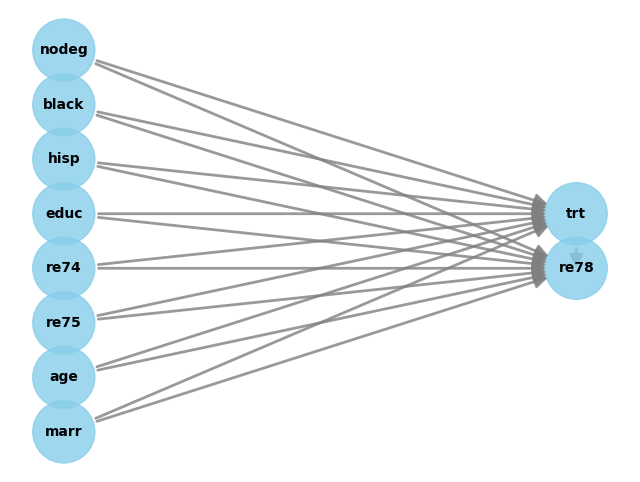

In [21]:
model = CausalModel(
data=df,
treatment='trt',
outcome='re78',
graph=gml
)
model.view_model()

# AUGMENTED INVERSE PROBABILITY WEIGHTING  (AIPW)

Is a model-agnostic framework that combines a propensity score model, e(x), with outcome regression models, μ₁(x) and μ₀(x), ensuring estimator consistency as long as at least one of the two components is correctly specified (the double robustness property).

It is indicated when there is uncertainty about the correct specification of either the propensity score model or the outcome model — the DR estimator provides protection against misspecification of either component, unlike pure IPW or pure regression adjustment.  


***AIPW***:$$\hat\tau_{ATE_{AIPW}}= \frac{1}{N}(\sum^N\frac{T_i(Y_i-\mu_1(X_i)}{\hat e(X_i)}+\mu_1(X_i))-\frac{1}{N}(\sum^N\frac{(1-T_i)(Y_i-\mu_0(X_i))}{1- \hat e(X_i)}+\mu_0(X_i))$$

- $\hat e(X)$ -> GMM
- $mu_0,mu_1$ -> best prediction model fitted on the data partions (T=1,T=0)

(https://github.com/PacktPublishing/Causal-Inference-and-Discovery-in-Python) (Ch 10 p.219)


# GMM
## PROPENSITY SCORE

Propensity Score $\hat{e}(X) = P(T=1 \mid X=x)$: measures the probability that a unit receives treatment $T=1$ given its covariate vector $x$.  


### CLUSTER PROPENSITY SCORE 
The propensity score is obtained via Bayes' rule from class-conditional densities, each fitted with its own GMM (one on treated units, one on controls):

$$e(x)=P(T=1\mid x)=\frac{\pi_1 f_1(x)}{\pi_1 f_1(x)+\pi_0 f_0(x)},\qquad \pi_1=\bar T,\ \pi_0=1-\pi_1$$

Here $f_1(x)=\sum_k w_k^{(1)}\,\mathcal N(x;\mu_k^{(1)},\Sigma_k^{(1)})$ is the treated mixture (same form for $f_0$), and score_samples returns $\log f_t(x)$.

The ratio is computed in log-space for stability: log_num $=\log\pi_1+\log f_1$, log_den $=\operatorname{logaddexp}(\log\pi_1+\log f_1,\ \log\pi_0+\log f_0)$, and $e=\exp(\text{log\_num}-\text{log\_den})$.

The result is then clipped to $[0.05,0.95]$ so that the weights $1/e$ and $e/(1-e)$ stay bounded

In [22]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

RANDOM_STATE = 42

features = ['age', 'educ', 'black', 'hisp', 'marr', 'nodeg','re74', 're75']

In [23]:
def preprocess_pca(df):
    X_all = df.values
    # Preprocessing of the data
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_all)

    return X_scaled

In [24]:
def gmm_propensity_score(X, T, n_components_treated=1, n_components_control=2, 
                          random_state=0, clip=0.05, reg_covar=1e-2, cov_type='diag'):
    X1, X0 = X[T == 1], X[T == 0]
    pi1, pi0 = T.mean(), 1 - T.mean()

    gmm1 = GaussianMixture(n_components=n_components_treated, 
                            covariance_type=cov_type, reg_covar=reg_covar,
                            random_state=random_state).fit(X1)
    gmm0 = GaussianMixture(n_components=n_components_control, 
                            covariance_type=cov_type, reg_covar=reg_covar,
                            random_state=random_state).fit(X0)

    log_f1 = gmm1.score_samples(X)
    log_f0 = gmm0.score_samples(X)

    log_num = np.log(pi1) + log_f1
    log_den = np.logaddexp(np.log(pi1) + log_f1, np.log(pi0) + log_f0)
    e_hat = np.exp(log_num - log_den)

    return np.clip(e_hat, clip, 1 - clip), gmm1, gmm0

In [25]:
def grid_search_propensity_score(X, T, pca_options, reg_covar_options, cov_type_options,
                                  n_components_treated_options, n_components_control_options):

    results = []
    X_preprocessed = preprocess_pca(X)   
    
    print('Grid search ...')
    for n_pca in pca_options:
        
        pca_test = PCA(n_components=n_pca, random_state=42)
        X_pca_test = pca_test.fit_transform(X_preprocessed)
        var_explained = pca_test.explained_variance_ratio_.sum()

        X1 = X_pca_test[T == 1]
        X0 = X_pca_test[T == 0]

        
        for reg_covar, cov_type, n_comp_t, n_comp_c in itertools.product(
            reg_covar_options, cov_type_options,n_components_treated_options, n_components_control_options):

            
            # print(f'La combinazione provata è {n_pca, reg_covar, cov_type, n_comp_t, n_comp_c}')
    
            try:
                e_hat_test, gmm1_test, gmm0_test = gmm_propensity_score(
                    X_pca_test, T,
                    n_components_treated=n_comp_t,
                    n_components_control=n_comp_c,
                    clip=0.0,
                    reg_covar=reg_covar,
                    cov_type=cov_type,
                )
            except Exception:
                continue

            overlap = ((e_hat_test > 0.1) & (e_hat_test < 0.9)).sum()

            results.append({
                'n_pca': n_pca, 'reg_covar': reg_covar, 'cov_type': cov_type,
                'n_components_treated': n_comp_t, 'n_components_control': n_comp_c,
                'overlap': overlap, 'e_hat_std': e_hat_test.std(),
                'var_explained_pca': var_explained,
                'bic_treated': gmm1_test.bic(X1),
                'bic_control': gmm0_test.bic(X0),
            })

    return pd.DataFrame(results).sort_values('overlap', ascending=False)

In [26]:
pca_options = [2, 3, 4, 5]
reg_covar_options = [1e-3, 1e-2, 5e-2, 1e-1, 5e-1]
cov_type_options = ['diag', 'tied', 'spherical']
n_components_treated_options=[1, 2]     
n_components_control_options=[1, 2, 3, 5]

result = grid_search_propensity_score(df[features], df['trt'].values, pca_options, reg_covar_options, cov_type_options,n_components_treated_options, n_components_control_options )
print(result.head())

Grid search ...
     n_pca  reg_covar   cov_type  n_components_treated  n_components_control  \
163      3      0.010  spherical                     1                     5   
259      4      0.001  spherical                     1                     5   
283      4      0.010  spherical                     1                     5   
19       2      0.001  spherical                     1                     5   
139      3      0.001  spherical                     1                     5   

     overlap  e_hat_std  var_explained_pca  bic_treated  bic_control  
163      443   0.165758           0.675481  1585.426060  8416.935661  
259      442   0.185488           0.798857  2044.958893  9451.611281  
283      442   0.187895           0.798857  2044.969130  9493.891062  
19       434   0.158921           0.528342  1039.022145  5645.944752  
139      433   0.165960           0.675481  1585.419919  8393.756901  


In [27]:
pca_options = [2, 3, 4, 5, 6]
reg_covar_options = [1e-3, 1e-2, 5e-2, 1e-1, 5e-1]
cov_type_options = ['diag', 'tied', 'full', 'spherical']
n_components_treated_options=[1, 2]     # tieni basso, hai solo 185 trattati
n_components_control_options=[1, 2, 3, 5]
result_nsw = grid_search_propensity_score(df_nsw[features], df_nsw['trt'].values, pca_options, reg_covar_options, cov_type_options,n_components_treated_options, n_components_control_options )
print(result_nsw.head())

Grid search ...
     n_pca  reg_covar   cov_type  n_components_treated  n_components_control  \
472      4       0.50  spherical                     1                     1   
768      6       0.50       diag                     1                     1   
760      6       0.10  spherical                     1                     1   
152      2       0.50  spherical                     1                     1   
88       2       0.05  spherical                     1                     1   

     overlap  e_hat_std  var_explained_pca  bic_treated  bic_control  
472      445   0.061694           0.783899  2487.805963  3470.391758  
768      445   0.071836           0.926021  3412.479809  4726.615479  
760      445   0.095911           0.926021  3430.910183  4778.891340  
152      445   0.056499           0.454710  1272.998554  1833.511160  
88       445   0.071988           0.454710  1261.829736  1820.278042  


In [28]:
BEST_N_PCA = 3
BEST_REG_COVAR = 0.01
BEST_COV_TYPE = 'spherical'
BEST_COMP_TRT = 1
BEST_COMP_CNTR = 5

pca_best = PCA(n_components=BEST_N_PCA, random_state=42)
X_pca_best = pca_best.fit_transform(preprocess_pca(df[features]))

e_hat, gmm1_final, gmm0_final = gmm_propensity_score(
    X_pca_best,  df['trt'].values,
    n_components_treated= BEST_COMP_TRT,
    n_components_control= BEST_COMP_CNTR,
    clip=0.05,
    reg_covar=BEST_REG_COVAR,
    cov_type=BEST_COV_TYPE,
)

In [29]:
# Overlap is the same, we choose based on BIC
BEST_N_PCA = 2
BEST_REG_COVAR = 0.5
BEST_COV_TYPE = 'spherical'
BEST_COMP_TRT = 1
BEST_COMP_CNTR = 1

pca_best = PCA(n_components=BEST_N_PCA, random_state=42)
X_pca_best = pca_best.fit_transform(preprocess_pca(df_nsw[features]))

e_hat_nsw, gmm1_final, gmm0_final = gmm_propensity_score(
    X_pca_best,  df_nsw['trt'].values,
    n_components_treated= BEST_COMP_TRT,
    n_components_control= BEST_COMP_CNTR,
    clip=0.05,
    reg_covar=BEST_REG_COVAR,
    cov_type=BEST_COV_TYPE,
)

# STANDARDIZED DIFFERENCES FOR COMPARING MEAN AND PREVALENCES BETWEEN GROUPS

Covariate balance. For each continuous covariate we compute the standardized mean difference

$$d=\frac{\bar x_{\text{trt}}-\bar x_{\text{con}}}{\sqrt{(s^2_{\text{trt}}+s^2_{\text{con}})/2}}$$

Unlike a $t$-test $p$-value, $d$ does not depend on sample size, so it measures imbalance directly and it gives the effect of the propensity score, and $|d|<0.1$ is the usual threshold for adequate balance.   (https://onlinelibrary.wiley.com/doi/epdf/10.1002/sim.3697) (Sec. 3.2)

In [30]:
X_df = df[features]
T = df['trt'].values
X_df_nsw = df_nsw[features]
T_nsw = df_nsw['trt'].values

# baseline pre-weighting
def smd(x, t):
    x1, x0 = x[t == 1], x[t == 0]
    mean_diff = x1.mean() - x0.mean()
    pooled_std = np.sqrt((x1.var(ddof=1) + x0.var(ddof=1)) / 2)
    return mean_diff / pooled_std if pooled_std > 0 else np.nan

def weighted_mean(x, w):
    return np.sum(w * x) / np.sum(w)

def weighted_var(x, w, mean):
    # variance weighted
    return np.sum(w * (x - mean) ** 2) / np.sum(w)


# SMD with weight
def weighted_smd(x, t, w):
    x1, w1 = x[t == 1], w[t == 1]
    x0, w0 = x[t == 0], w[t == 0]
    m1, m0 = weighted_mean(x1, w1), weighted_mean(x0, w0)
    v1 = weighted_var(x1, w1, m1)
    v0 = weighted_var(x0, w0, m0)
    pooled_std = np.sqrt((v1 + v0) / 2)
    return (m1 - m0) / pooled_std if pooled_std > 0 else np.nan

In [31]:
smd_raw_nsw = {col: smd(X_df_nsw[col].values, T_nsw) for col in features}
smd_raw = {col: smd(X_df[col].values, T) for col in features}


# ipw
w_nsw = np.where(T_nsw == 1, 1 / e_hat_nsw, 1 / (1 - e_hat_nsw))
w = np.where(T == 1, 1 / e_hat, 1 / (1 - e_hat))

# SMD with weight
smd_weighted_nsw = {col: weighted_smd(X_df_nsw[col].values, T_nsw, w_nsw) for col in features}
smd_weighted = {col: weighted_smd(X_df[col].values, T, w) for col in features}


# df for comaprison
balance_df_nsw = pd.DataFrame({
    "SMD_raw": smd_raw_nsw,
    "SMD_weighted": smd_weighted_nsw
})
    
balance_df = pd.DataFrame({
    "SMD_raw": smd_raw,
    "SMD_weighted": smd_weighted
})
print('SMD (Lalonde Sample)\n\n', balance_df_nsw.round(4) )
print('\n\nSMD (Combined dataset)\n\n', balance_df.round(4))

SMD (Lalonde Sample)

        SMD_raw  SMD_weighted
age     0.1073        0.0472
educ    0.1412        0.0118
black   0.0439       -0.1063
hisp   -0.1746        0.0063
marr    0.0936        0.0635
nodeg  -0.3040       -0.1924
re74   -0.0022       -0.0098
re75    0.0839        0.0999


SMD (Combined dataset)

        SMD_raw  SMD_weighted
age     0.8302        0.5098
educ   -0.0081        0.2269
black   1.9852        0.8633
hisp    0.0108        0.3401
marr    0.2770        0.3704
nodeg  -0.1076       -0.2783
re74   -0.1324        0.4052
re75   -0.2749        0.2928


## REGRESSION MODELS

We split our data on the treatment variable, which gives us two subsets: the subset of all treated observations and a subset of all untreated observations. We fit two separate models, one to each subset of the data. These are our first-stage base learners $\mu_0,\mu_1$

In [32]:
# Splitting the data on the treatment value

df_trt_nsw = df_nsw[df_nsw['trt'] == 1]
df_cntr_nsw = df_nsw[df_nsw['trt'] == 0]
df_trt = df[df['trt'] == 1]
df_cntr = df[df['trt'] == 0]

In [33]:
pipe_rf = Pipeline([("model", RandomForestRegressor(random_state=RANDOM_STATE))])
param_grid_rf = {
    "model__n_estimators": [200],
    "model__max_depth": [None, 5, 10],
    "model__max_features": [None, 0.7],       
    "model__min_samples_leaf": [1, 2, 4],
}

pipe_gb = Pipeline([("model", GradientBoostingRegressor(random_state=RANDOM_STATE))])
param_grid_gb = {
    "model__n_estimators": [100, 300],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3],
    "model__subsample": [0.8, 1.0],
    "model__max_features": [None, 0.7],
}

pipelines = {
    "Random Forest": (pipe_rf, param_grid_rf),
    "Gradient Boosting": (pipe_gb, param_grid_gb),
}

In [34]:
def run_nested_cv(
    X, y,
    pipelines,
    outer_splits=5,
    inner_splits=3,
    random_state=42):

    X = np.asarray(X)
    y = np.asarray(y)

    outer_cv = KFold(n_splits=outer_splits, shuffle=True, random_state=random_state)
    inner_cv = KFold(n_splits=inner_splits, shuffle=True, random_state=random_state)

    results_nsw = []
    print('Running Nested CV...')
    for pipe_name, (pipe, param_grid) in pipelines.items():
        
        # print(f"\n{'='*70}")
        # print(f"Valutazione pipeline: {pipe_name}")
        # print(f"{'='*70}")

        for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), start=1):
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            search = GridSearchCV(
                estimator=pipe,
                param_grid=param_grid,
                scoring="neg_root_mean_squared_error",
                cv=inner_cv,
                n_jobs=-1
            )
            search.fit(X_train, y_train)

            best_model = search.best_estimator_
            y_pred = best_model.predict(X_test)

            r2 = r2_score(y_test, y_pred)
            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mae = mean_absolute_error(y_test, y_pred)

            results_nsw.append({
                "pipeline": pipe_name,
                "fold": fold,
                "inner_best_rmse": -search.best_score_,
                "outer_r2": r2,
                "outer_rmse": rmse,
                "outer_mae": mae,
                "best_params": search.best_params_
            })

            # print(f"Fold {fold}")
            # print(f"  Best params: {search.best_params_}")
            # print(f"  Inner CV best RMSE: {(-search.best_score_):.4f}")
            # print(f"  Outer R2:           {r2:.4f}")
            # print(f"  Outer RMSE:         {rmse:.4f}")

    results_df = pd.DataFrame(results_nsw)

    print("\n\nRisultati per fold:")
    print(results_df[["pipeline", "fold", "inner_best_rmse", "outer_r2", "outer_rmse"]])

    summary = (
        results_df
        .groupby("pipeline")[["inner_best_rmse", "outer_r2", "outer_rmse"]]
        .agg(["mean", "std"])
    )
    summary.columns = ["_".join(col) for col in summary.columns]
    summary = summary.sort_values("outer_rmse_mean", ascending=True)

    print("\n\nRiassunto finale (nested CV):")
    print(summary)

    best_pipeline_name = summary.index[0]
    print(f"\nMigliore pipeline in media (RMSE esterno più basso): {best_pipeline_name}")


    return results_df, summary

In [35]:
X_nsw = df_trt_nsw[features].values
y_nsw =  df_trt_nsw['re78'].values

X = df_trt[features].values
y =  df_trt['re78'].values

In [36]:
results_df_nswt, summary_nswt = run_nested_cv(X_nsw, y_nsw, pipelines)

Running Nested CV...


Risultati per fold:
            pipeline  fold  inner_best_rmse  outer_r2    outer_rmse
0      Random Forest     1      8280.765691  0.020796   6446.505379
1      Random Forest     2      8033.124477 -0.063386   7514.560802
2      Random Forest     3      8650.116529 -0.216583   5202.977814
3      Random Forest     4      6920.320534 -0.152887  10897.432374
4      Random Forest     5      7771.975835 -0.100851   9457.730737
5  Gradient Boosting     1      8241.279333  0.015270   6464.672210
6  Gradient Boosting     2      8080.938074 -0.030364   7396.964610
7  Gradient Boosting     3      8492.116617 -0.193507   5153.396250
8  Gradient Boosting     4      7138.591739 -0.096052  10625.428502
9  Gradient Boosting     5      7903.736982 -0.102165   9463.373976


Riassunto finale (nested CV):
                   inner_best_rmse_mean  inner_best_rmse_std  outer_r2_mean  \
pipeline                                                                      
Gradient Boosting  

In [37]:
best_pipeline_name = summary_nswt.index[0]

best_fold_row = (
    results_df_nswt[results_df_nswt["pipeline"] == best_pipeline_name]
    .sort_values("outer_rmse")
    .iloc[0]
)
best_params = best_fold_row["best_params"]

pipe, _ = pipelines[best_pipeline_name]
pipe.set_params(**best_params)
pipe.fit(X, y)   # fit diretto su tutto il dataset, niente CV
mu_1_nsw = pipe.predict(df_nsw[features].values)

In [38]:
results_df_trt, summary_trt = run_nested_cv(X, y, pipelines)

Running Nested CV...


Risultati per fold:
            pipeline  fold  inner_best_rmse  outer_r2    outer_rmse
0      Random Forest     1      8198.160673 -0.095221   6616.571183
1      Random Forest     2      8760.050201 -0.081508   5493.251647
2      Random Forest     3      8499.808117 -0.036090   6733.271808
3      Random Forest     4      6965.347843 -0.010829  11261.791489
4      Random Forest     5      7952.636935  0.012097   8357.516166
5  Gradient Boosting     1      8575.185616 -0.215245   6969.699602
6  Gradient Boosting     2      9234.372467 -0.141490   5643.527842
7  Gradient Boosting     3      8815.394390 -0.814191   8909.820838
8  Gradient Boosting     4      7091.544808 -0.017854  11300.853646
9  Gradient Boosting     5      7901.396834 -0.007710   8440.886138


Riassunto finale (nested CV):
                   inner_best_rmse_mean  inner_best_rmse_std  outer_r2_mean  \
pipeline                                                                      
Random Forest      

In [39]:
best_pipeline_name = summary_trt.index[0]

best_fold_row = (
    results_df_trt[results_df_trt["pipeline"] == best_pipeline_name]
    .sort_values("outer_rmse")
    .iloc[0]
)
best_params = best_fold_row["best_params"]

pipe, _ = pipelines[best_pipeline_name]
pipe.set_params(**best_params)
pipe.fit(X, y)   
mu_1 = pipe.predict(df[features].values)

In [40]:
# vedo come cambia nel subset dei dati trattati

Totale combinazioni generate: 6


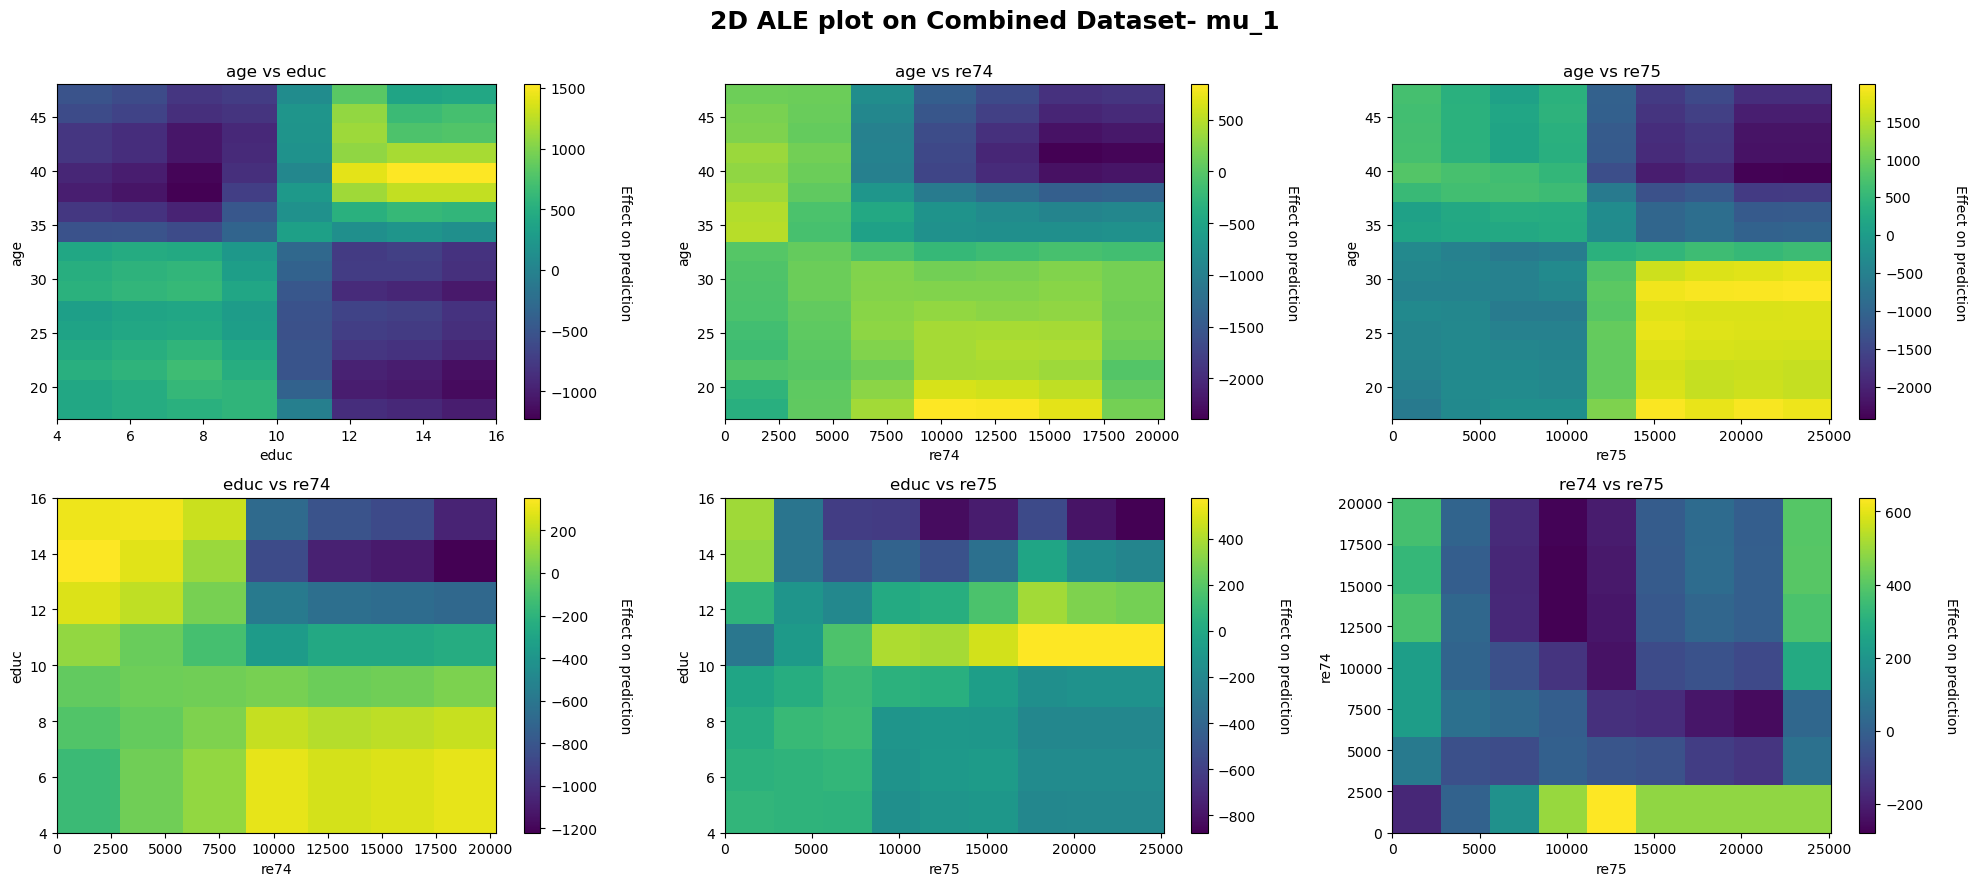

In [41]:
# 1. Definizione X e y
best_features = ['age', 'educ', 're74', 're75']
X = df_trt[best_features]
y =  df_trt['re78'].values

# 2. Addestramento
pipe, _ = pipelines[best_pipeline_name]
pipe.set_params(**best_params)
pipe.fit(X, y)   

# 3. Creazione delle combinazioni
coppie_features = list(itertools.combinations(best_features, 2))
num_plots = len(coppie_features)

print(f"Totale combinazioni generate: {num_plots}")

# 4. Impostazione della griglia (4 colonne)
cols = 3
rows = math.ceil(num_plots / cols)

# Creiamo la figura con le dimensioni proporzionate al numero di righe
# figsize=(larghezza, altezza_per_riga * numero_righe)
fig, axes = plt.subplots(rows, cols, figsize=(20, 4.5 * rows))

# Appiattiamo la matrice degli assi (da 2D a 1D) per iterare facilmente con un singolo indice
axes = axes.flatten() 

# 5. Generazione degli ALE plot 2D nella griglia
for i, coppia in enumerate(coppie_features):
    ax = axes[i] # Selezioniamo l'asse corrente
    
    ale_eff = ale(
        X=X, 
        model=pipe,          
        feature=list(coppia),
        grid_size=20,        
        plot=True,
        fig=fig,
        ax=ax                # Passiamo l'asse specifico della griglia
    )
    
    ax.set_title(f'{coppia[0]} vs {coppia[1]}', fontsize=12)


# Aggiustiamo gli spazi per evitare che i titoli e gli assi si sovrappongano
# Aggiunge un titolo generale a tutta la griglia
fig.suptitle('2D ALE plot on Combined Dataset- mu_1', fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('ale_interazioni_mu1.png', dpi=300, bbox_inches='tight')
plt.show()

In [42]:
X_nsw = df_cntr_nsw[features].values
y_nsw =  df_cntr_nsw['re78'].values

X = df_cntr[features].values
y =  df_cntr['re78'].values

In [43]:
results_df_nswc, summary_nswc = run_nested_cv(X_nsw, y_nsw, pipelines)

Running Nested CV...


Risultati per fold:
            pipeline  fold  inner_best_rmse  outer_r2   outer_rmse
0      Random Forest     1      5775.689251 -0.480860  5640.057443
1      Random Forest     2      5885.811263  0.005429  4680.917086
2      Random Forest     3      5746.652558  0.014152  5168.837882
3      Random Forest     4      5169.582714 -0.104858  6648.886552
4      Random Forest     5      5276.827586 -0.175046  6621.997622
5  Gradient Boosting     1      5703.336989 -0.166118  5004.927748
6  Gradient Boosting     2      5875.672267 -0.006527  4708.968682
7  Gradient Boosting     3      5973.269298  0.058115  5052.274360
8  Gradient Boosting     4      5121.487653 -0.131803  6729.474020
9  Gradient Boosting     5      5364.506498 -0.079862  6348.127384


Riassunto finale (nested CV):
                   inner_best_rmse_mean  inner_best_rmse_std  outer_r2_mean  \
pipeline                                                                      
Gradient Boosting           56

In [44]:
best_pipeline_name = summary_nswc.index[0]

best_fold_row = (
    results_df_nswc[results_df_nswc["pipeline"] == best_pipeline_name]
    .sort_values("outer_rmse")
    .iloc[0]
)
best_params = best_fold_row["best_params"]

pipe, _ = pipelines[best_pipeline_name]
pipe.set_params(**best_params)
pipe.fit(X, y)   
mu_0_nsw = pipe.predict(df_nsw[features].values)

In [45]:
results_df_cntr, summary_cntr = run_nested_cv(X, y, pipelines)

Running Nested CV...


Risultati per fold:
            pipeline  fold  inner_best_rmse  outer_r2   outer_rmse
0      Random Forest     1      6083.502374  0.200199  6008.252149
1      Random Forest     2      5911.921937  0.039912  6513.102536
2      Random Forest     3      6202.327978  0.174921  5626.992650
3      Random Forest     4      6080.249306  0.149361  5987.607687
4      Random Forest     5      6006.268351  0.084169  6085.208071
5  Gradient Boosting     1      6036.702385  0.178525  6089.119533
6  Gradient Boosting     2      5930.255692  0.036894  6523.333404
7  Gradient Boosting     3      6197.021465  0.181435  5604.737477
8  Gradient Boosting     4      6073.890427  0.137939  6027.670018
9  Gradient Boosting     5      6012.102288  0.099108  6035.375184


Riassunto finale (nested CV):
                   inner_best_rmse_mean  inner_best_rmse_std  outer_r2_mean  \
pipeline                                                                      
Random Forest               60

In [46]:
best_pipeline_name = summary_cntr.index[0]

best_fold_row = (
    results_df_cntr[results_df_cntr["pipeline"] == best_pipeline_name]
    .sort_values("outer_rmse")
    .iloc[0]
)
best_params = best_fold_row["best_params"]

pipe, _ = pipelines[best_pipeline_name]
pipe.set_params(**best_params)
pipe.fit(X, y)   
mu_0 = pipe.predict(df[features].values)

In [47]:
# vedo come cambia nel subset dei dati non trattati

In [48]:
features

['age', 'educ', 'black', 'hisp', 'marr', 'nodeg', 're74', 're75']

Totale combinazioni generate: 6


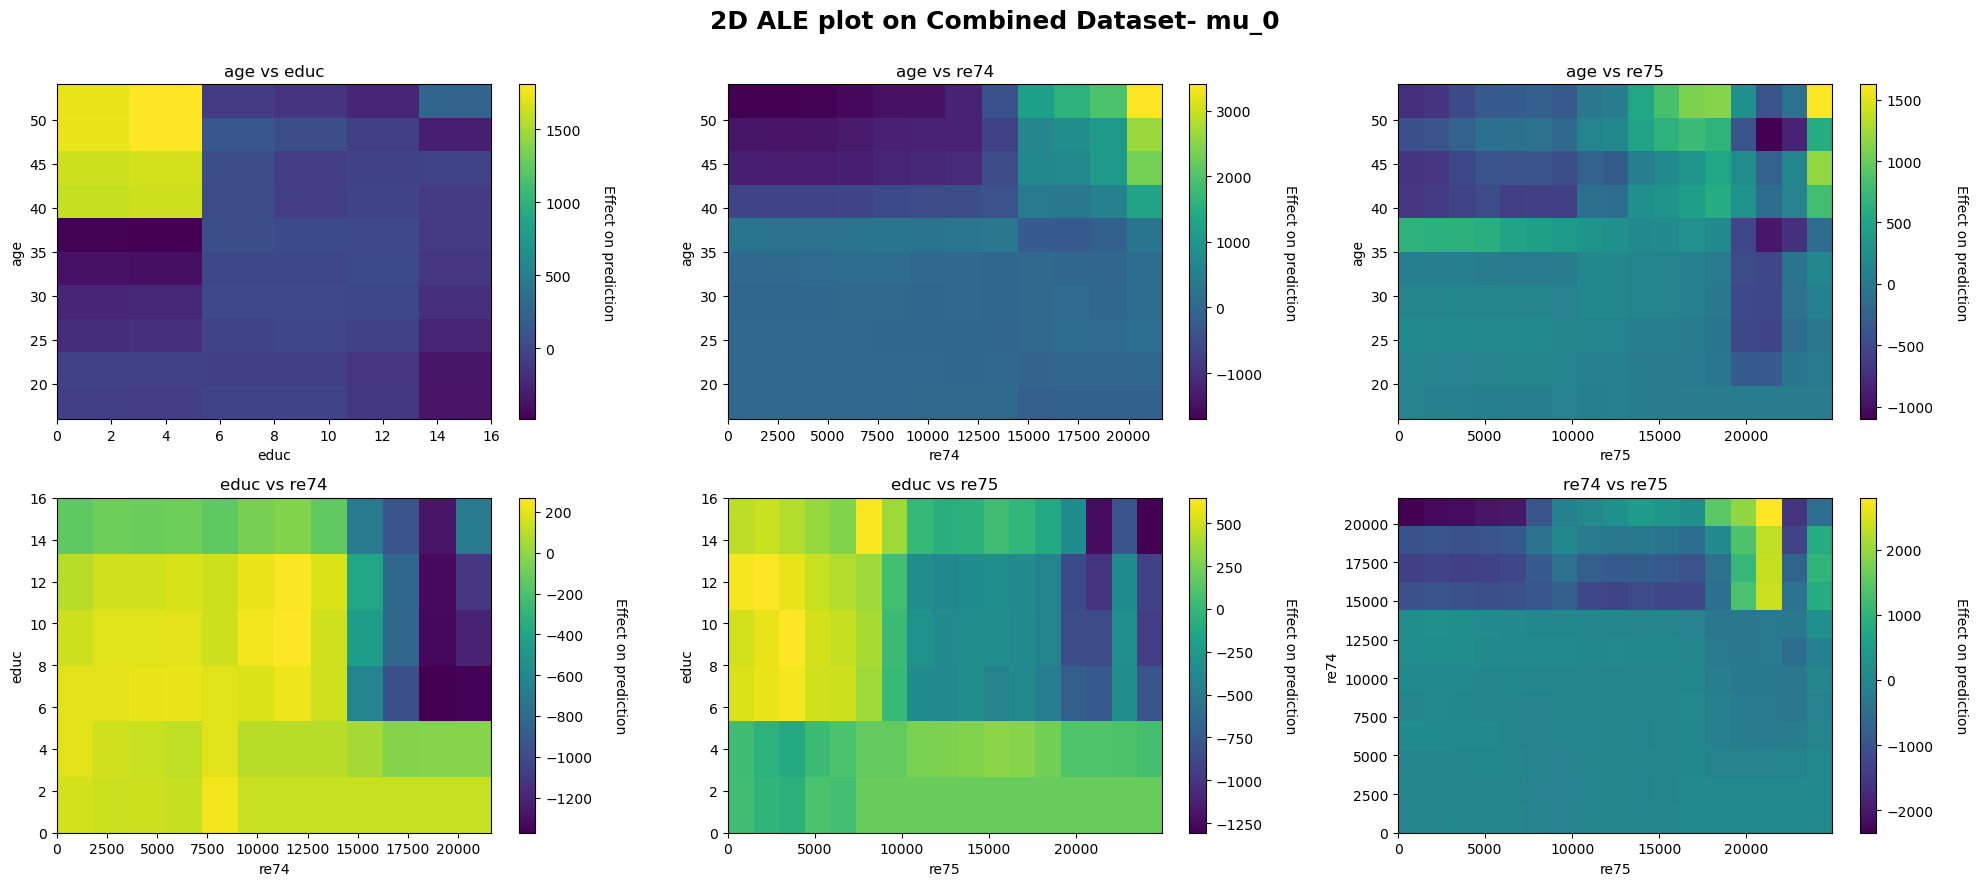

In [49]:
# 1. Definizione X e y
best_features = ['age', 'educ', 're74', 're75']
X = df_cntr[best_features]
y =  df_cntr['re78'].values

# 2. Addestramento
pipe, _ = pipelines[best_pipeline_name]
pipe.set_params(**best_params)
pipe.fit(X, y)   

# 3. Creazione delle combinazioni
coppie_features = list(itertools.combinations(best_features, 2))
num_plots = len(coppie_features)

print(f"Totale combinazioni generate: {num_plots}")

# 4. Impostazione della griglia (4 colonne)
cols = 3
rows = math.ceil(num_plots / cols)

# Creiamo la figura con le dimensioni proporzionate al numero di righe
# figsize=(larghezza, altezza_per_riga * numero_righe)
fig, axes = plt.subplots(rows, cols, figsize=(20, 4.5 * rows))

# Appiattiamo la matrice degli assi (da 2D a 1D) per iterare facilmente con un singolo indice
axes = axes.flatten() 

# 5. Generazione degli ALE plot 2D nella griglia
for i, coppia in enumerate(coppie_features):
    ax = axes[i] # Selezioniamo l'asse corrente
    
    ale_eff = ale(
        X=X, 
        model=pipe,          
        feature=list(coppia),
        grid_size=20,        
        plot=True,
        fig=fig,
        ax=ax                # Passiamo l'asse specifico della griglia
    )
    
    ax.set_title(f'{coppia[0]} vs {coppia[1]}', fontsize=12)


# Aggiustiamo gli spazi per evitare che i titoli e gli assi si sovrappongano
# Aggiunge un titolo generale a tutta la griglia
fig.suptitle('2D ALE plot on Combined Dataset- mu_0', fontsize=18, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig('ale_interazioni_mu0.png', dpi=300, bbox_inches='tight')
plt.show()

# THE OUTCOME MODELS

In the presence of small sample sizes and a low signal-to-noise ratio, the base learners for the outcome model ($\hat{\mu}_0, \hat{\mu}_1$) may exhibit limited explanatory power (low $R^2$).  

However, the use of the AIPW ($\hat{\tau}_{AIPW}$) guarantees the consistency of the Average Treatment Effect (ATE) provided that at least one of the two underlying processes—either the outcome model or the propensity score $e(X)$—is correctly specified. 

DR estimate of ATE: $$\hat\tau_{ATE_{AIPW}}= \frac{1}{N}(\sum^N\frac{T_i(Y_i-\mu_1(X_i)}{\hat e(X_i)}+\mu_1(X_i))-\frac{1}{N}(\sum^N\frac{(1-T_i)(Y_i-\mu_0(X_i))}{1- \hat e(X_i)}+\mu_0(X_i))$$

In [50]:
naive = df_nsw.loc[df_nsw['trt']==1, 're78'].mean() - df_nsw.loc[df_nsw['trt']==0, 're78'].mean()
print(f"Naive diff-in-means on NSW dataset: {naive:.2f}")

Naive diff-in-means on NSW dataset: 1794.34


In [51]:
T_nsw = df_nsw['trt'].values
Y_nsw = df_nsw['re78'].values

term_treated = T_nsw  * (Y_nsw - mu_1_nsw) / e_hat_nsw + mu_1_nsw
term_control = (1 - T_nsw ) * (Y_nsw - mu_0_nsw) / (1 - e_hat_nsw) + mu_0_nsw

tau_ate = np.mean(term_treated) - np.mean(term_control)


print(f"ATE (DR) on NSW dataset: {tau_ate:.2f}")

ATE (DR) on NSW dataset: 1649.94


In [52]:
IF_dr = term_treated - term_control - tau_ate

N_nsw = len(IF_dr)
var_IF_dr = np.var(IF_dr)          
SE_dr = np.sqrt(var_IF_dr / N_nsw)

CI_lower_dr = tau_ate - 1.96 * SE_dr
CI_upper_dr = tau_ate + 1.96 * SE_dr

print(f"ATE (AIPW) on NSW dataset: {tau_ate:.2f}")
print(f"SE:       {SE_dr:,.2f} $")
print(f"CI 95%:   [{CI_lower_dr:,.2f}, {CI_upper_dr:,.2f}] $")

ATE (AIPW) on NSW dataset: 1649.94
SE:       640.60 $
CI 95%:   [394.36, 2,905.53] $


In [53]:
naive = df.loc[df['trt']==1, 're78'].mean() - df.loc[df['trt']==0, 're78'].mean()
print(f"Naive diff-in-means on Combined dataset: {naive:.2f}")

Naive diff-in-means on Combined dataset: -864.95


In [54]:
T = df['trt'].values
Y = df['re78'].values

term_treated = T * (Y - mu_1) / e_hat + mu_1
term_control = (1 - T) * (Y - mu_0) / (1 - e_hat) + mu_0

tau_ate = np.mean(term_treated) - np.mean(term_control)


print(f"ATE (DR) on Combined dataset: {tau_ate:.2f}")

ATE (DR) on Combined dataset: 384.63


In [55]:
IF_dr = term_treated - term_control - tau_ate

N_nsw = len(IF_dr)
var_IF_dr = np.var(IF_dr)          
SE_dr = np.sqrt(var_IF_dr / N_nsw)

CI_lower_dr = tau_ate - 1.96 * SE_dr
CI_upper_dr = tau_ate + 1.96 * SE_dr

print(f"ATE (AIPW) on Combined dataset: {tau_ate:.2f}")
print(f"SE:       {SE_dr:,.2f} $")
print(f"CI 95%:   [{CI_lower_dr:,.2f}, {CI_upper_dr:,.2f}] $")

ATE (AIPW) on Combined dataset: 384.63
SE:       367.88 $
CI 95%:   [-336.41, 1,105.66] $


# CONCLUSIONS

The experimental benchmark for the NSW dataset, reported by LaLonde (1986) and confirmed by Chen et al. (2024), is 1,794.34. On the pure NSW sample, where the naive difference aligns with this experimental result, the proposed Doubly Robust method slightly underperforms and is the only 95% interval that excludes zero and contains the experimental value. Conversely, on the combined dataset, applying the proposed DR estimator—utilizing a GMM-based propensity score alongside RandomForest or GradientBosst for the outcome models—yields an underperforming ATE. This effectively reverses the severe negative bias of the naive difference (-864.95), though it still falls short of the true experimental benchmark.

Even after applying the proposed matching and propensity score balancing to the combined dataset, the observational control group remains structurally distinct from the treated group, reflecting the limited overlap intrinsic to the Lalonde setting. Given the inherent difficulty of the dataset, the outcome models exhibit relatively low explanatory power, and this weak fit propagates directly into estimation bias.

In light of this, we explore Targeted Maximum Likelihood Estimation (TMLE) to reweight the covariate distributions more effectively, ensuring stable estimation while rigorously preserving the double robustness property of the baseline DR framework.